In [1]:
# imports
%pip install -q  gdown opencv-python-headless matplotlib pandas scikit-learn keras_tuner mlflow
# from google.colab import drive
import os
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import tensorflow as tf
from pathlib import Path
import sys
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.applications import MobileNetV2
from sklearn.model_selection import train_test_split


import keras_tuner as kt
# print("GPU:", tf.config.list_physical_devices("GPU"))



Note: you may need to restart the kernel to use updated packages.


2026-10-23 16:15:20.874760: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792772120.899857   23563 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792772120.907658   23563 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792772120.927383   23563 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792772120.927404   23563 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792772120.927407   23563 computation_placer.cc:177] computation placer alr

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [2]:

import gdown 
import zipfile 
import os 

file_id =  "1WfBc-5ql3BfQBw4dGnnsiHxYH_-gZZFG"
url = f'https://drive.google.com/uc?id={file_id}'

output = "workspace/data.zip"
directory_of_data = "/workspace/NeuroVision/Data"

if not os.path.isdir(directory_of_data) : 
    
    if not os.path.isfile(output) : 
        
        gdown.download(url , output , quiet=False)
        
        with zipfile.ZipFile(output, 'r') as zip_ref : 
            
            zip_ref.extractall(directory_of_data)
        
    else : 
          
          
        with zipfile.ZipFile(output, 'r') as zip_ref : 
            
            zip_ref.extractall(directory_of_data)
        
    
dataset_path = "/workspace/NeuroVision/Data/Data"

print(os.listdir(dataset_path))





['glioma', 'meningioma', 'notumor', 'pituitary']


In [3]:
## EDA : 
import tensorflow as tf


# loading the data
"""dataset_path = "../data/Data"  """ 
"""dataset_path = "/kaggle/input/datasets/mohamedaminerahmani/neurrron/Data"
images_no_tumor_path = os.path.join(dataset_path, "notumor")"""





'dataset_path = "/kaggle/input/datasets/mohamedaminerahmani/neurrron/Data"\nimages_no_tumor_path = os.path.join(dataset_path, "notumor")'

In [4]:
# data folders :

data_folders = os.listdir(dataset_path)
data_folders

['glioma', 'meningioma', 'notumor', 'pituitary']

In [5]:
folder_extensions = {}
valid_extensions= ["jpeg", "jpg" , "bmp", "png"]

for folder in data_folders :

    images_paths = os.listdir(os.path.join(dataset_path, folder))


    for image_path in images_paths :

        extension = image_path.split(".")[1]
        
        if folder not in folder_extensions :
            folder_extensions[folder]  = []
       
        if extension not in valid_extensions : 
            print(f"Extension is not valid {extension} in {folder} folder")
            break
            
        if extension not in folder_extensions[folder] :
            folder_extensions[folder].append(extension)



In [6]:
# preprocessing : 

# get images with their labels and also it is shuffled as a return : 
from sklearn.utils import shuffle
def load_images(dataset_path , data_folders) :
     
    images = []
    
    labels = []
    
    for folder in data_folders : 
        for image_path in os.listdir(os.path.join(dataset_path , folder)) : 
            
            image = cv2.imread(os.path.join(dataset_path , folder , image_path))
            
            image = cv2.cvtColor(image , cv2.COLOR_BGR2RGB)
            
            images.append(image)
            labels.append(folder)
            
            
            
            
    
    return images , labels



images , labels = load_images(dataset_path, data_folders)




In [7]:
images , labels =  shuffle(images , labels , random_state=42)
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)

np.unique(labels_encoded)



array([0, 1, 2, 3])

In [8]:

# resizing : 

images = [
    cv2.resize(image , (224, 224))
    for image in images 
]



In [9]:
# processing using  => preprocess_input()

images = np.array(images ,dtype=np.float32)

images = preprocess_input(images)



In [10]:

x_train , x_test , y_train , y_test = train_test_split(
    images , 
    labels_encoded ,
    random_state=42, 
    test_size=0.2, 
    stratify=labels_encoded
)


x_train , x_val_train , y_train , y_val_train  = train_test_split(
    x_train ,
    y_train,
    random_state=42,
    test_size=0.10,
    stratify=y_train
)


In [11]:

# data augmentation : only for training : 


data_augmentation = tf.keras.Sequential([
    
    layers.RandomRotation(0.03), 
    
    layers.RandomZoom(0.1), 
    
    layers.RandomTranslation(
        height_factor=0.05, 
        width_factor=0.05
    )
])



I0000 00:00:1792772146.491359   23563 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10255 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:03:00.0, compute capability: 8.6


In [12]:
# Load MobileNet V2 : 

base_model = MobileNetV2(
    weights="imagenet", 
    include_top=False,
    input_shape=(224, 224 , 3)
)


base_model.trainable = False 



In [13]:
# define the model : 
learning_rate = 0.0001

def build_model() : 
        
    inputs = layers.Input(shape=(224, 224, 3))
    
    # data augmentation : 
    x = data_augmentation(inputs)
    
    # freez the weights : 
    x = base_model(x , training=False)
    
    # classification head : 
    
    x = layers.GlobalAveragePooling2D()(x)
    
    x = layers.Dense(128, activation="relu")(x)
    
    x= layers.Dropout(0.3)(x)
    
    outputs = layers.Dense(4 , activation="softmax")(x)
    
    model = models.Model(inputs , outputs)
    

    model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
    )
    
    return model 





In [14]:


# implementing keras tuner so i can choose best epochs : 

"""
tuner = kt.Hyperband(
    hypermodel=build_model, 
    objective="val_accuracy", 
    max_epochs=20, 
    directory="my_logs", 
    project_name="simple_hyperband"
)


tuner.search(x_train , y_train , validation_data=(x_val_train, y_val_train))


best_model = tuner.get_best_models(num_models=1)

best_hps

"""

'\ntuner = kt.Hyperband(\n    hypermodel=build_model, \n    objective="val_accuracy", \n    max_epochs=20, \n    directory="my_logs", \n    project_name="simple_hyperband"\n)\n\n\ntuner.search(x_train , y_train , validation_data=(x_val_train, y_val_train))\n\n\nbest_model = tuner.get_best_models(num_models=1)\n\nbest_hps\n\n'

In [15]:
# training :

import tensorflow as tf
import time
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("NeuroVision 2")


start_time = time.perf_counter()

with mlflow.start_run() : 
    
    epochs = 30
    BATCH_SIZE = 16
    
    mlflow.log_param("model_name", "MobileNetv2")
    mlflow.log_param("epochs", epochs)
    mlflow.log_param("learning_rate", learning_rate)
    mlflow.log_param("image_size", "224x224")
    mlflow.log_param("num_clusses", 4)
    mlflow.log_param("optimizer", "Adam")
    def train_transfer_learning() : 
        
        
        
        
        
        global history
        checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath="/workspace/transferlearning.keras", 
        monitor="val_loss",
        save_best_only=True,
        mode="min" 
        )
        
        
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", 
            patience=3,
            min_delta=0.001 ,
            restore_best_weights=True, 
            mode="min"
        )
        model = build_model()
        history = model.fit(
            x_train , 
            y_train , 
            validation_data=(x_val_train, y_val_train) , 
            epochs=epochs , 
            batch_size=BATCH_SIZE, 
            callbacks=[checkpoint , early_stopping]
            
        )
        
        for epoch , metrics in enumerate(history.history["accuracy"]) : 
            
            mlflow.log_metric(
                "train_accuracy", 
                metrics , 
                step=epoch
            )
        for epoch , metrics in enumerate(history.history["val_accuracy"]) : 
            
            mlflow.log_metric(
                "val_accuracy",
                metrics, 
                step=epoch
            )
        
        for epoch , metrics in enumerate(history.history["val_loss"]) :  
              
            mlflow.log_metric(
                "val_loss", 
                metrics , 
                step=epoch
            )
        
        
        for epoch , metrics in enumerate(history.history["loss"]) :  
                     
            mlflow.log_metric(
                "train_loss", 
                metrics , 
                step=epoch
            )
            
            
        
        mlflow.tensorflow.log_model(
            model , 
            name="mobilenet_transfer_learning"
        )
        
    


    

if not os.path.isfile("/workspace/transferlearning.keras") :  
    train_transfer_learning()
    
duration = time.perf_counter() - start_time




print(f"Training duration: {duration:.2f} seconds")
print(f"Training duration: {duration / 60:.2f} minutes")


mlflow.end_run()



🏃 View run capable-lamb-324 at: http://127.0.0.1:5000/#/experiments/2/runs/ed743fcf84a243d59bc4a237375c9426
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
Epoch 1/30


I0000 00:00:1792772163.406538   23735 cuda_dnn.cc:529] Loaded cuDNN version 92400


316/316 ━━━━━━━━━━━━━━━━━━━━ 22s 45ms/step - accuracy: 0.5789 - loss: 1.0105 - val_accuracy: 0.7972 - val_loss: 0.5430
Epoch 2/30
316/316 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.8154 - loss: 0.4877 - val_accuracy: 0.8114 - val_loss: 0.4544
Epoch 3/30
316/316 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.8585 - loss: 0.3851 - val_accuracy: 0.8292 - val_loss: 0.4456
Epoch 4/30
316/316 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.8726 - loss: 0.3409 - val_accuracy: 0.8541 - val_loss: 0.3711
Epoch 5/30
316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.8820 - loss: 0.3199 - val_accuracy: 0.8416 - val_loss: 0.3765
Epoch 6/30
316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.9017 - loss: 0.2705 - val_accuracy: 0.8488 - val_loss: 0.3793
Epoch 7/30
316/316 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.8927 - loss: 0.2932 - val_accuracy: 0.8470 - val_loss: 0.3812


2026/10/23 16:17:32 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


Training duration: 114.46 seconds
Training duration: 1.91 minutes
🏃 View run honorable-bat-539 at: http://127.0.0.1:5000/#/experiments/2/runs/ff899e3759d1468eb1fdb61e31e1de1a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


In [16]:
# save model : 



In [17]:
# visualization :  

if not os.path.isfile("/workspace/transferlearning.keras") :
    plt.figure(figsize=(10, 5))
    
    plt.plot(history.history["accuracy"],  label="Training")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.title("Model accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

In [18]:
if not os.path.isfile("/workspace/transferlearning.keras") :
    plt.figure(figsize=(10, 5))
    
    plt.plot(history.history["loss"],  label="Training loss")
    plt.plot(history.history["val_loss"], label="Validation loss")
    
    plt.title("training  vs val  loss")
    plt.xlabel("Epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.show()

In [19]:
dataset_path = "/workspace/NeuroVision/Data/Data"

image = os.listdir(os.path.join(dataset_path, "notumor"))
image

image = cv2.imread(os.path.join(dataset_path, "notumor", "Te-no_0050.jpg"))




In [20]:
# i found a researcher mad ethe same project we have and made a model but i cant change on its strucutre ,  




    
    
# implementing mednet model for medical images : 
CLASS_NAMES = ["notumor" , "glioma", "meningioma", "pituitary"]



"""base_med_model = tf.saved_model.load(
    "/workspace/brain_tumor_cnn_improved"
)"""
  
    
def preprocess(image_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_image(img, channels=1, expand_animations=False)  # force grayscale
    img = tf.image.resize(img, (192, 192))
    img = tf.cast(img, tf.float32) / 255.0   # assumed scaling to [0, 1]
    return tf.expand_dims(img, axis=0)       # shape: (1, 192, 192, 1)
    

def predict(image_path):
    x = preprocess(image_path)

    # Use the serving signature if available, otherwise call the model directly
    if hasattr(base_med_model, "signatures") and "serving_default" in base_med_model.signatures:
        infer = base_med_model.signatures["serving_default"]
        out = infer(**{list(infer.structured_input_signature[1].keys())[0]: x})
        preds = list(out.values())[0].numpy()
    else:
        preds = base_med_model(x).numpy()

    probs = preds[0]
    # If the outputs aren't already probabilities, apply softmax
    if not np.isclose(probs.sum(), 1.0, atol=1e-3):
        probs = tf.nn.softmax(probs).numpy()

    idx = int(np.argmax(probs))
    print(f"Prediction: {CLASS_NAMES[idx]} ({probs[idx]*100:.1f}%)")
    for name, p in zip(CLASS_NAMES, probs):
        print(f"  {name:<12} {p*100:.1f}%")
    return CLASS_NAMES[idx], probs
    




In [21]:
# load the pretrained model  : 

class_names = ["glioma", "meningioma", "notumor", "pituitary"]
loaded_model = tf.keras.models.load_model("/workspace/transferlearning.keras")


predictions = loaded_model.predict(x_test)

results = np.argmax(predictions, axis=1)







44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step


In [24]:
# fine tunning : 


loaded_model

with mlflow.start_run() : 
    learning_rate = 0.0001
    epochs = 30
    BATCH_SIZE = 32
        
    mlflow.log_param("model_name", "MobileNetv2")
    mlflow.log_param("epochs", epochs)
    mlflow.log_param("learning_rate", learning_rate)
    mlflow.log_param("image_size", "224x224")
    mlflow.log_param("num_clusses", 4)
    mlflow.log_param("optimizer", "Adam")
    
    
    
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath="/workspace/finetunning.keras", 
        monitor="val_loss", 
        save_best_only=True, 
        mode="min"
    )
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3 , 
        min_delta=0.001, 
        restore_best_weights=True, 
        mode="min"
    )
    
    loaded_model.trainable = True 
    
    for layer in loaded_model.layers[:-20] : 
        layer.trainable = False 
        
        
    
    loaded_model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate,  
        ),
        loss="sparse_categorical_crossentropy", 
        metrics=["accuracy"],
        )
    
    
    
        
    history = loaded_model.fit(x_train , y_train , validation_data=(x_val_train, y_val_train), epochs=epochs , callbacks=[checkpoint , early_stopping], batch_size=BATCH_SIZE)

   
    for epoch , metrics in enumerate(history.history["accuracy"]) : 
               
        mlflow.log_metric(
            "train_accuracy", 
            metrics , 
            step=epoch
        )
    for epoch , metrics in enumerate(history.history["val_accuracy"]) : 
               
        mlflow.log_metric(
            "val_accuracy",
            metrics, 
            step=epoch
        )
           
    for epoch , metrics in enumerate(history.history["val_loss"]) :  
                 
        mlflow.log_metric(
            "val_loss", 
            metrics , 
            step=epoch
        )
           
           
    for epoch , metrics in enumerate(history.history["loss"]) :  
                        
        mlflow.log_metric(
            "train_loss", 
            metrics , 
            step=epoch
        )
               
               
           
    mlflow.tensorflow.log_model(
        loaded_model , 
        name="mobilenet_finetunning"
    )
           


mlflow.end_run()


Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 16s 75ms/step - accuracy: 0.9400 - loss: 0.1602 - val_accuracy: 0.9057 - val_loss: 0.2531
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - accuracy: 0.9422 - loss: 0.1594 - val_accuracy: 0.8932 - val_loss: 0.2740
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - accuracy: 0.9481 - loss: 0.1506 - val_accuracy: 0.8986 - val_loss: 0.2586
Epoch 4/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - accuracy: 0.9488 - loss: 0.1485 - val_accuracy: 0.9021 - val_loss: 0.2512
Epoch 5/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - accuracy: 0.9497 - loss: 0.1376 - val_accuracy: 0.9057 - val_loss: 0.2512
Epoch 6/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 57ms/step - accuracy: 0.9520 - loss: 0.1349 - val_accuracy: 0.8932 - val_loss: 0.2826
Epoch 7/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 57ms/step - accuracy: 0.9476 - loss: 0.1445 - val_accuracy: 0.8915 - val_loss: 0.2818


2026/10/23 16:24:45 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run valuable-duck-925 at: http://127.0.0.1:5000/#/experiments/2/runs/1eb574abb7814463930c6c2614ec9659
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/10/23 14:46:25 INFO mlflow.tracking.fluent: Experiment with name 'NeuroVision' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1792766785455, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792766785455, lifecycle_stage='active', name='NeuroVision', tags={}, trace_location=None, workspace='default'>

In [ ]:
# load fine tunning model 


fine_tunning_model = tf.keras.models.load_model("/workspace/finetunning.keras")


predictions_of_tunning = fine_tunning_model.predict(x_test)

y_pred  = np.argmax(predictions_of_tunning, axis=1)



44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step


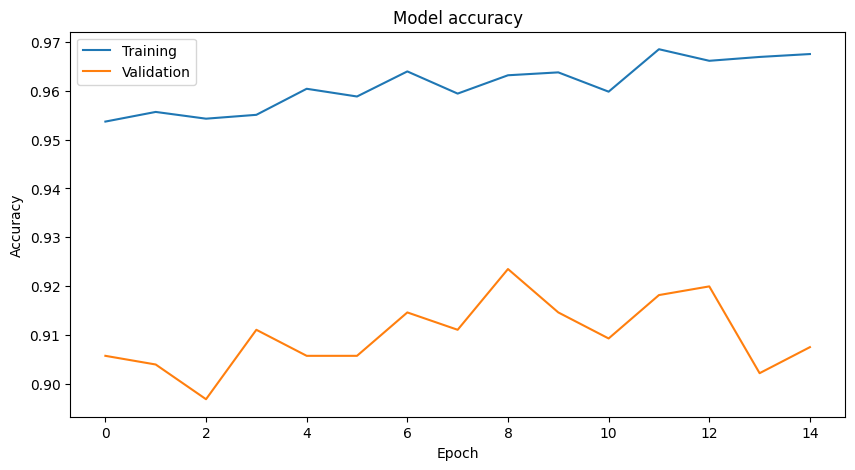

In [ ]:


plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"],  label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Model accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

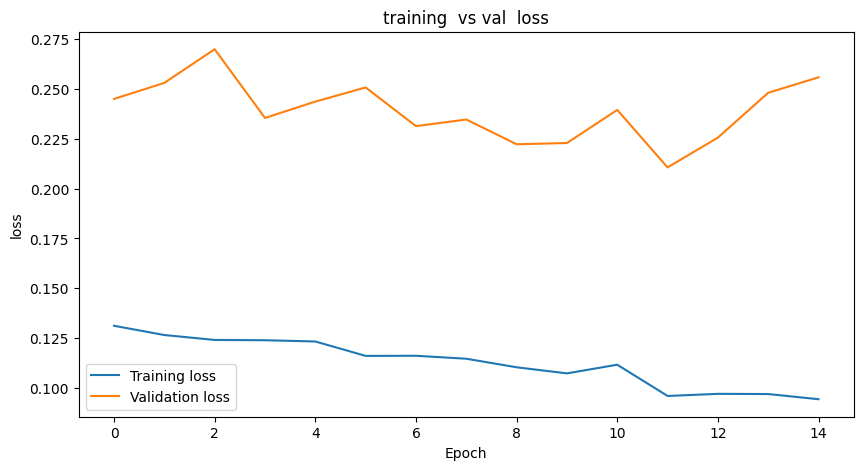

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"],  label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.title("training  vs val  loss")
plt.xlabel("Epoch")
plt.ylabel("loss")
plt.legend()
plt.show()